# Part 3: Data quality in weather and reservoir filling

This notebook prepares eight reproducible weather locations and demonstrates
DCT/SPC, Local Outlier Factor (LOF), STL, and a spectrogram. The notebook and
Streamlit app import the same analysis functions; visible checks accompany each
step. The demonstration uses **NO3 weather in 2024** and **all available NO3
weekly filling history**.

The [official IND320 course material](https://khliland.github.io/IND320/) is the
course reference. The [Part 3 assignment](https://nmbu.instructure.com/courses/14185/assignments/59074)
requires a Canvas login; this implementation follows the agreed local plan.

## Run locally

Use Python 3.10. From the repository root, run `uv sync --group notebook`, then
`uv run jupyter lab` and open this notebook. Select the project Python kernel
and run every cell in order. Start the app with `uv run streamlit run app.py`.
The two public APIs require internet access; no API keys or databases are needed
for Part 3. GIS libraries belong only to the notebook dependency group.

The shapefile folders and `data/weather_coordinates.csv` are included in Git.
Running the sampling cell regenerates the CSV with seed 320. The existing Part 1
and Part 2 notebooks are retained separately.

In [1]:
# Run from the repository root and embed plots in the notebook and PDF.
%matplotlib inline
from pathlib import Path
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ind320.config import ROOT
from ind320.data.areas import load_weather_areas, sample_weather_points
from ind320.data.weather import fetch_weather, daily_weather, load_weather_coordinates
from ind320.data.reservoirs import fetch_reservoir_history
from ind320.analysis.weather import precipitation_analysis, temperature_analysis
from ind320.analysis.reservoirs import weekly_filling, stl_analysis, filling_spectrogram

# Bare notebook execution does not have a Streamlit session; suppress its cache notices.
logging.getLogger("streamlit").setLevel(logging.ERROR)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Project root:", ROOT.name)

2026-10-31 09:37:48.071 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-31 09:37:48.072 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


Project root: IND320


## Area definitions and reproducible sampling

`Budomraader/` supplies NO1-NO5 electricity-area polygons. `NVE_Region/` supplies
five administrative regions. East combines **RS + RØ**, West uses **RV**, and
North combines **RM + RN**. These three groups approximate precipitation areas;
they are **not exact catchment boundaries** or exact VASS boundaries. We do not
compare the grouped weather polygons numerically with VASS areas here. NO3
weather and EL 3 filling share an electricity-area label, but one weather point
still cannot represent precipitation over the whole area.

Both files use EPSG:25833 (ETRS89 / UTM zone 33N). We draw random coordinates
uniformly within each projected bounding box and retain only points strictly
inside its polygon. We keep 1,000 candidates for each of the eight areas, then
randomly choose one candidate per area. One NumPy generator with **seed 320**
controls both stages. This is sampling in projected coordinates, not uniform
sampling of latitude/longitude boxes. Only the eight chosen points are sent to
WGS84 (EPSG:4326) for CSV use; candidates are also returned in WGS84 for checks
and plotting. Sampling 1,000 candidates does not mean 1,000 API downloads.

The NVE DBF needs explicit UTF-8 decoding to preserve the code RØ. The loading
function checks that all expected electricity and region codes are present.

In [2]:
# Prepare all eight polygons, sample candidates, and save the chosen API coordinates.
areas = load_weather_areas()
candidates, chosen = sample_weather_points(areas, count=1000, seed=320)
coordinates = chosen.assign(
    latitude=chosen.geometry.y, longitude=chosen.geometry.x
)[["area", "latitude", "longitude"]]
(ROOT / "data").mkdir(exist_ok=True)
coordinate_path = ROOT / "data" / "weather_coordinates.csv"
coordinates.to_csv(coordinate_path, index=False, float_format="%.8f")
display(coordinates.round(5))

,area,latitude,longitude
0,NO1,59.83469,10.58618
1,NO2,59.22612,6.69521
2,NO3,61.43172,5.41610
3,NO4,67.82270,15.99120
4,NO5,60.38271,4.55572
5,East,60.09849,10.11488
6,West,62.86050,7.28856
7,North,62.54329,11.58147


In [3]:
# Visible sampling checks: counts, containment, deterministic reruns, and CSV contents.
assert len(areas) == 8 and areas.geometry.is_valid.all()
assert candidates.groupby("area").size().eq(1000).all()
projected_candidates = candidates.to_crs(areas.crs)
projected_chosen = chosen.to_crs(areas.crs)
for area, polygon in areas.geometry.items():
    assert projected_candidates.loc[candidates["area"] == area].within(polygon).all()
    assert projected_chosen.loc[chosen["area"] == area].within(polygon).all()
_, repeated = sample_weather_points(areas, count=1000, seed=320)
assert chosen.equals(repeated)
saved = load_weather_coordinates()
assert len(saved) == 8 and saved.index.is_unique
assert set(saved.index) == set(areas.index)
assert np.allclose(saved[["latitude", "longitude"]], coordinates[["latitude", "longitude"]])
print("PASS: 1,000 interior points per area; eight reproducible coordinates saved.")

PASS: 1,000 interior points per area; eight reproducible coordinates saved.


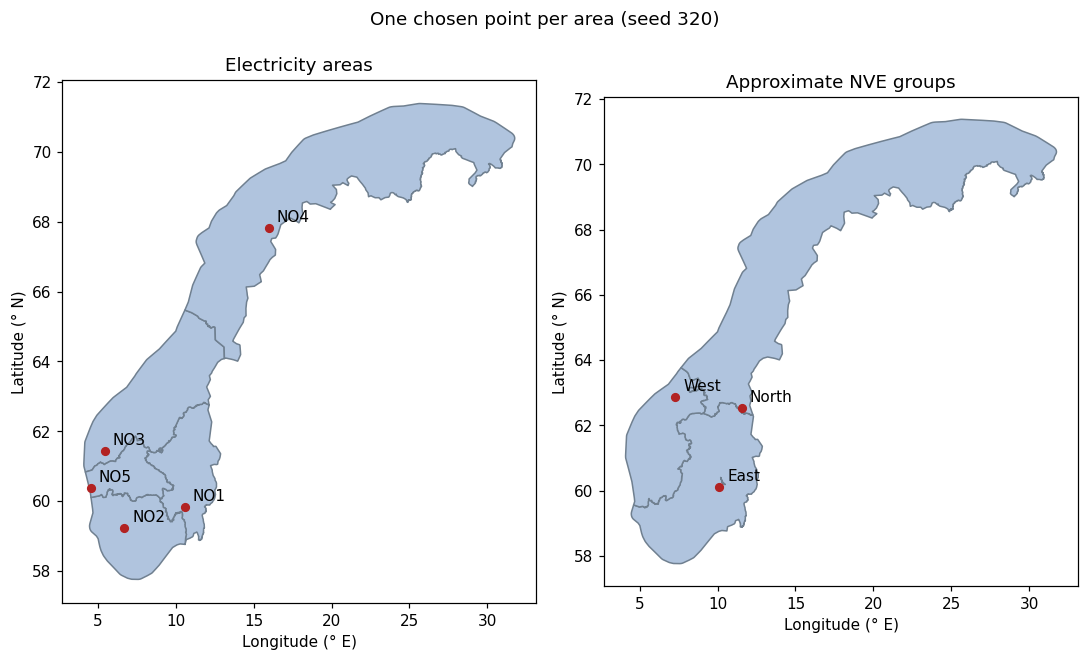

In [4]:
# Show both area systems separately because their polygons overlap one another.
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, names, title in zip(
    axes, [list(areas.index[:5]), list(areas.index[5:])],
    ["Electricity areas", "Approximate NVE groups"]
):
    areas.loc[names].to_crs(4326).plot(ax=ax, color="lightsteelblue", edgecolor="slategray")
    chosen.loc[chosen["area"].isin(names)].plot(ax=ax, color="firebrick", markersize=25)
    for row in chosen.loc[chosen["area"].isin(names)].itertuples():
        ax.annotate(row.area, (row.geometry.x, row.geometry.y), xytext=(5, 4), textcoords="offset points")
    ax.set(title=title, xlabel="Longitude (° E)", ylabel="Latitude (° N)")
fig.suptitle("One chosen point per area (seed 320)")
fig.tight_layout()
plt.show()

## Hourly ERA5 weather for NO3, 2024

The [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
provides Copernicus ERA5 reanalysis. We explicitly request `models=era5`,
`precipitation`, `temperature_2m`, and `timezone=UTC` for January 1-December 31,
2024. UTC avoids daylight-saving gaps and duplicated hours. A complete leap year
has **8,784 hours and 366 days**. The downloader checks the complete hourly index
and rejects missing responses rather than silently filling them.

These values are model estimates at an ERA5 grid cell, not direct station
measurements. The returned grid coordinate may differ from the sampled point.
Precipitation is an hourly amount in millimeters. We average the 24 hourly amounts
per day as requested: the plotted daily quantity is an **average hourly amount
(mm), not a daily rainfall total**. Temperature is averaged in degrees Celsius.
Open-Meteo weather data use CC BY 4.0; attribution is retained in the app.

In [5]:
# One chosen coordinate, one full-year request; no candidate-point loop over the API.
hourly = fetch_weather("NO3", "2024-01-01", "2024-12-31")
daily = daily_weather(hourly)
print("Chosen point:", hourly.attrs["latitude"], hourly.attrs["longitude"])
print("ERA5 grid cell:", hourly.attrs["grid_latitude"], hourly.attrs["grid_longitude"])
display(daily.head())

Chosen point: 61.43171828 5.41610441
ERA5 grid cell: 61.5 5.5


,precipitation,temperature_2m
time,,
2024-01-01 00:00:00+00:00,0.012500,-0.716667
2024-01-02 00:00:00+00:00,0.008333,-3.787500
2024-01-03 00:00:00+00:00,0.000000,-7.887500
2024-01-04 00:00:00+00:00,0.000000,-10.083333
2024-01-05 00:00:00+00:00,0.000000,-14.137500


In [6]:
# Check leap-year coverage, UTC, source units, and correct daily averaging.
expected_hours = pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h", tz="UTC")
assert hourly.index.equals(expected_hours) and len(hourly) == 8784
assert str(hourly.index.tz) == "UTC" and len(daily) == 366
assert hourly.notna().all().all() and np.isfinite(hourly.to_numpy()).all()
assert (hourly.precipitation >= 0).all()
assert np.allclose(daily.iloc[0], hourly.iloc[:24].mean())
assert np.allclose(daily.precipitation * 24, hourly.precipitation.resample("D").sum())
print("PASS: 8,784 complete UTC hours and 366 daily averages, including February 29.")

PASS: 8,784 complete UTC hours and 366 daily averages, including February 29.


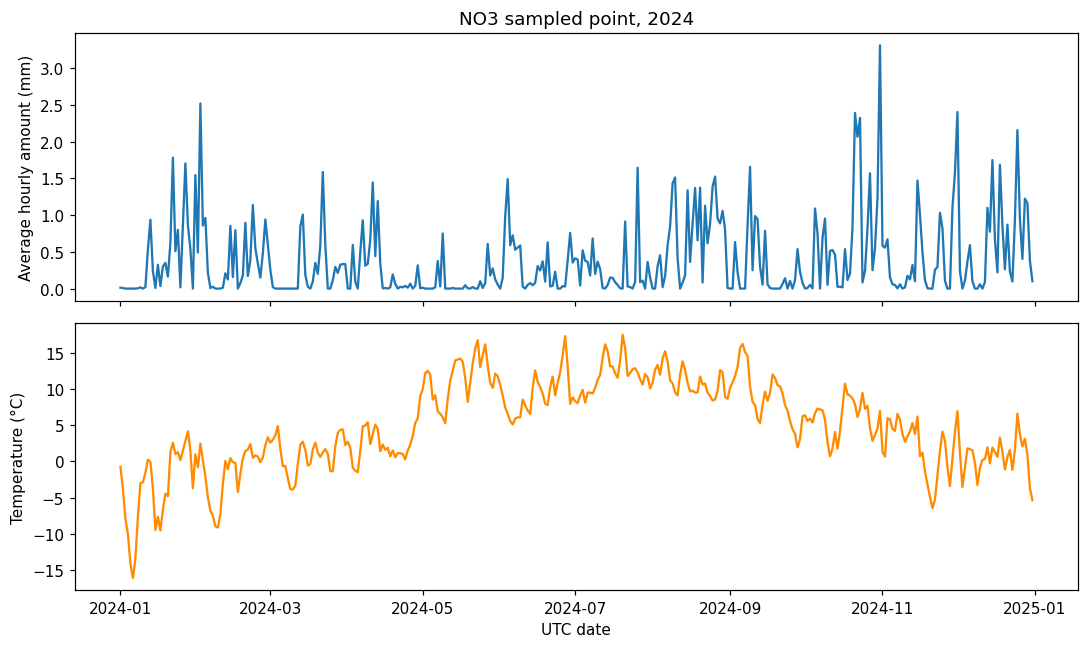

In [7]:
# Daily plots retain distinct units; averaging rainfall amounts is not summing them.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily.index, daily.precipitation)
axes[0].set(title="NO3 sampled point, 2024", ylabel="Average hourly amount (mm)")
axes[1].plot(daily.index, daily.temperature_2m, color="darkorange")
axes[1].set(xlabel="UTC date", ylabel="Temperature (°C)")
fig.tight_layout()
plt.show()

## Precipitation: DCT high-pass filter and robust SPC

The Discrete Cosine Transform (DCT) expresses the daily series as cosine
coefficients from slow to fast variation. We set the first **eight** coefficients
(including the mean) to zero and invert the transform. The remaining signal
emphasizes faster changes. Setting the cutoff to zero returns the original
series. Raising the cutoff removes more slow variation; it is not an exact
calendar-season adjustment. Eight coefficients over 366 days correspond roughly
to removing variations slower than a few months. Boundary effects and the
chosen interval can affect the result.

For robust statistical process control (SPC), calculate the median of the
filtered values and estimate sigma as **1.4826 × MAD**, where MAD is the median
absolute deviation from that median. Flag residuals outside median ± **3 sigma**
over the full selected year. If MAD is zero, the function explicitly falls back
to sample standard deviation. Limits are translated back onto the original
precipitation series so the flagged dates remain interpretable. Filtered amounts
and lower limits may be negative even though rainfall itself is nonnegative.

**Assignment wording conflict:** the task applies DCT to precipitation but calls
its output “seasonally adjusted temperature variations” in one sentence. This
implementation follows the precipitation instruction and labels the filtered
result as precipitation. No temperature interpretation is assigned to it.

Rainfall is skewed and autocorrelated, so these are exploratory SPC flags, not
calibrated normal-tail probabilities or proof of data errors. The cutoff and
multiplier are adjustable in the app.

{'days': 366, 'outliers': 24, 'center': -0.14947965752622902, 'sigma': 0.35351516933458904, 'scale_method': 'normal-scaled MAD'}


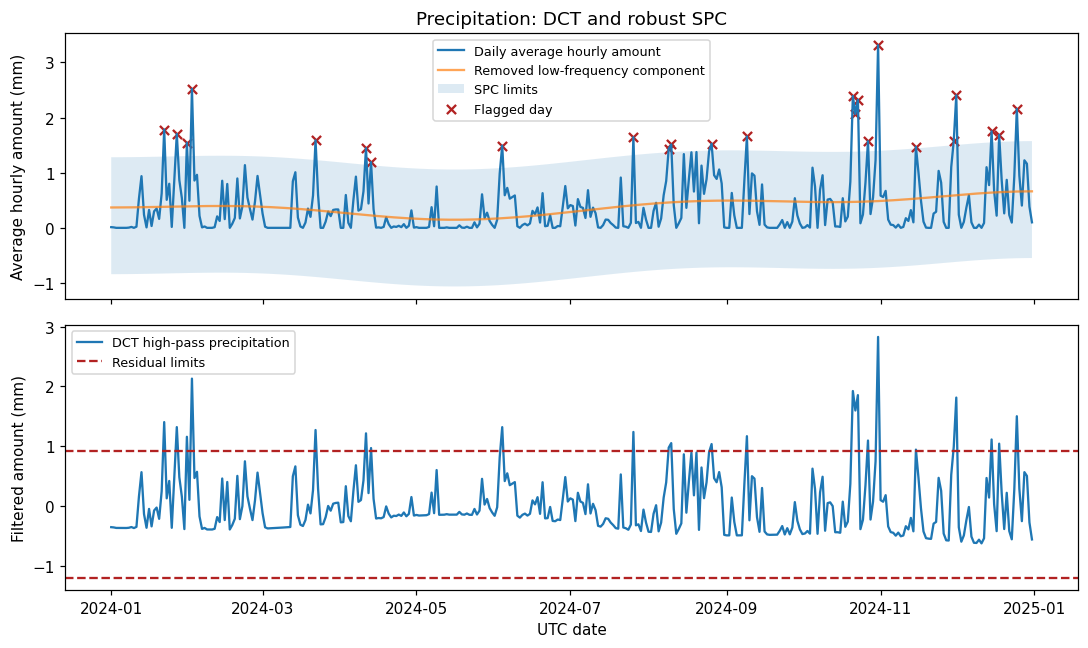

,precipitation,filtered
time,,
2024-01-22 00:00:00+00:00,1.783333,1.401558
2024-01-27 00:00:00+00:00,1.704167,1.317623
2024-01-31 00:00:00+00:00,1.545833,1.155684
2024-02-02 00:00:00+00:00,2.520833,2.129056
2024-03-22 00:00:00+00:00,1.587500,1.268936


In [8]:
# Shared analysis returns plot data, a concise summary, and the same figure used in the app.
precipitation, precipitation_summary, fig = precipitation_analysis(daily.precipitation)
print(precipitation_summary)
plt.show()
display(precipitation.loc[precipitation.outlier, ["precipitation", "filtered"]].head())

In [9]:
# Verify the transform, SPC flags, parameter effects, and constant inputs.
assert len(precipitation) == 366
assert np.allclose(precipitation.baseline + precipitation.filtered, daily.precipitation)
assert precipitation.outlier.equals(
    (precipitation.precipitation < precipitation.lower)
    | (precipitation.precipitation > precipitation.upper)
)
assert precipitation_summary["outliers"] == int(precipitation.outlier.sum())
no_filter, _, check_fig = precipitation_analysis(daily.precipitation, cutoff=0)
assert np.allclose(no_filter.filtered, daily.precipitation)
plt.close(check_fig)
more_filter, _, check_fig = precipitation_analysis(daily.precipitation, cutoff=16)
assert not np.allclose(more_filter.filtered, precipitation.filtered)
plt.close(check_fig)
wide_limits, _, check_fig = precipitation_analysis(daily.precipitation, multiplier=6)
assert wide_limits.outlier.sum() <= precipitation.outlier.sum()
plt.close(check_fig)
# Constant nonzero rainfall also checks that DCT roundoff cannot create flags.
for amount in [0.0, 1.0]:
    for cutoff in [0, 8]:
        constant, _, check_fig = precipitation_analysis(
            pd.Series(amount, index=daily.index), cutoff=cutoff
        )
        assert not constant.outlier.any() and np.isfinite(constant.filtered).all()
        plt.close(check_fig)
print("PASS: reconstruction, original-series flags, controls, and constant inputs.")

PASS: reconstruction, original-series flags, controls, and constant inputs.


In [10]:
# Inspect sensitivity instead of treating defaults as universal weather thresholds.
rows = []
for cutoff in [4, 8, 16]:
    for multiplier in [2.0, 3.0, 4.0]:
        _, summary, check_fig = precipitation_analysis(daily.precipitation, cutoff, multiplier)
        rows.append({"cutoff": cutoff, "multiplier": multiplier, "flagged_days": summary["outliers"]})
        plt.close(check_fig)
display(pd.DataFrame(rows).pivot(index="cutoff", columns="multiplier", values="flagged_days"))
print("Default flags (% of days):", round(100 * precipitation.outlier.mean(), 1))

multiplier,2.0,3.0,4.0
cutoff,,,
4,46,28,12
8,40,24,11
16,51,23,15


Default flags (% of days): 6.6


The default plot retains the daily wet spells and highlights a smaller set of
unusual days. The sensitivity table shows how the interpretation changes when
we remove more low-frequency structure or widen the boundary. We retain eight
coefficients and three sigma as an exploratory starting point, not an optimized
or validated decision rule. Inspect the dates and weather context before acting
on a flag; no flagged observations are deleted from the source data.

## Temperature: Local Outlier Factor

[Local Outlier Factor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html)
compares a value's local density with its neighbors' density. Here the input is
**daily average temperature alone** with 20 neighbors. Dates are used for plotting,
not as model features. A large positive LOF score indicates a relatively sparse
value. The default contamination of **1%** sets the score threshold; ties mean the
flagged count need not equal exactly 1% of 366. Increasing contamination flags
more temperatures. It is not a probability that the sensor is wrong.

This simple method can flag naturally rare winter or summer temperatures and
miss unusual temperatures for a particular season. It does not model temporal
context. The app exposes contamination while keeping the same one-feature model.

{'days': 366, 'outliers': 4, 'mean_c': 4.994387522768671, 'contamination': 0.01}


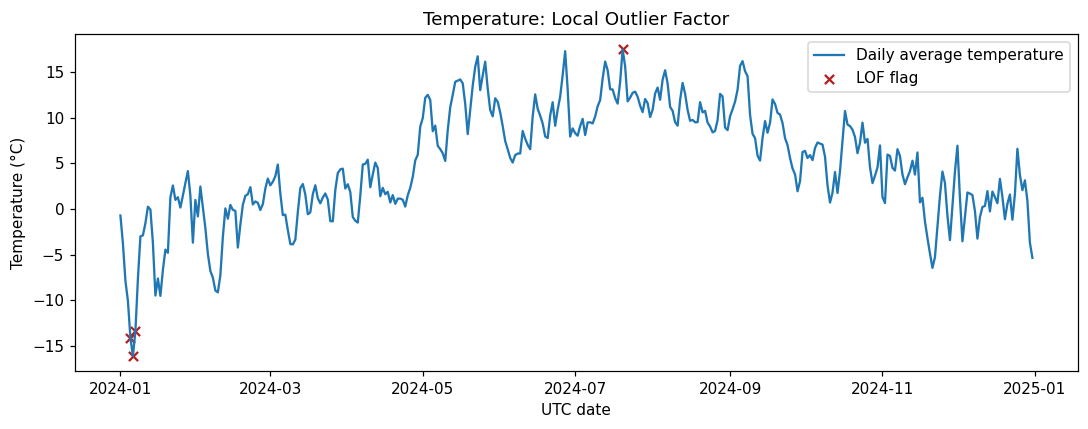

,temperature_2m,lof_score,outlier
time,,,
2024-01-05 00:00:00+00:00,-14.137500,2.355833,True
2024-01-06 00:00:00+00:00,-16.125000,2.871007,True
2024-01-07 00:00:00+00:00,-13.429167,2.207369,True
2024-07-20 00:00:00+00:00,17.508333,1.867584,True


In [11]:
# Highlight the detected dates on the original temperature timeline.
temperature, temperature_summary, fig = temperature_analysis(daily.temperature_2m)
print(temperature_summary)
plt.show()
display(temperature.loc[temperature.outlier])

In [12]:
# Check LOF output and the effect of moving the score threshold.
assert temperature.index.equals(daily.index)
assert np.allclose(temperature.temperature_2m, daily.temperature_2m)
assert np.isfinite(temperature.lof_score).all()
assert temperature_summary["outliers"] == int(temperature.outlier.sum())
more_flags, _, check_fig = temperature_analysis(daily.temperature_2m, contamination=0.05)
assert more_flags.outlier.sum() >= temperature.outlier.sum()
assert (more_flags.outlier | ~temperature.outlier).all()
plt.close(check_fig)
print("PASS: original temperatures retained; higher contamination includes the default flags.")

PASS: original temperatures retained; higher contamination includes the default flags.


## Full weekly reservoir history

The [NVE Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html)
returns all available filling observations. We select **EL 3 (NO3)**, independently
of the weather year. Fractions are converted to percentages once. Each row in the
series represents one week, not one month or one year.

STL and the spectrogram need equally spaced samples. The shared preparation
function creates a seven-day grid between the first and last available dates.
It interpolates only internal missing weeks in time and reports their count.
It rejects duplicate or off-grid dates rather than silently averaging them.
Interpolation can smooth local variation and must be considered when interpreting
the plots. At least 104 weeks are required for the two annual cycles.

In [13]:
# Use the existing cached public NVE downloader, without any month/year filter.
reservoir_source = fetch_reservoir_history()
weekly = weekly_filling(reservoir_source, "EL", 3)
print(f"NO3 full history: {weekly.index.min():%Y-%m-%d} to {weekly.index.max():%Y-%m-%d}")
print(f"{len(weekly)} weeks; {weekly.attrs['interpolated_weeks']} interpolated weeks.")
assert len(weekly) >= 104 and np.isfinite(weekly).all()
assert (weekly.index.to_series().diff().dropna() == pd.Timedelta(weeks=1)).all()
original = reservoir_source.loc[
    (reservoir_source["Area Type"] == "EL") & (reservoir_source["Area Code"] == 3)
].set_index("Observation Date")["Fill Level"]
assert np.allclose(weekly.loc[original.dropna().index], original.dropna() * 100)
# A deliberately removed internal week must be reported and interpolated.
gap_source = reservoir_source.copy()
gap_source = gap_source.loc[~(
    (gap_source["Area Type"] == "EL") & (gap_source["Area Code"] == 3)
    & (gap_source["Observation Date"] == weekly.index[10])
)]
gap_weekly = weekly_filling(gap_source, "EL", 3)
assert len(gap_weekly) == len(weekly)
assert gap_weekly.attrs["interpolated_weeks"] == weekly.attrs["interpolated_weeks"] + 1
print("PASS: weekly spacing, percentage conversion, full coverage, and gap reporting.")

2026-10-31 09:37:51.498 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-31 09:37:51.498 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NO3 full history: 1995-01-08 to 2026-10-25
1660 weeks; 0 interpolated weeks.
PASS: weekly spacing, percentage conversion, full coverage, and gap reporting.


## STL: trend, seasonality, and residuals

[STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html)
uses local smoothing to decompose observed filling into additive trend, seasonal,
and residual components. The seasonal **period is fixed at 52 weeks**, an
approximation to a calendar year that also contains occasional ISO week 53.

The seasonal smoother defaults to **13** and governs how much the seasonal pattern
can change across years. The trend smoother defaults to **105 weeks**; increasing
it produces a slower trend. Both lengths must be odd, and the trend must exceed
52. Robust fitting defaults to true and reduces the effect of large residuals.
The app exposes all three settings. Component sizes use percentage points (pp),
while the original filling level is shown as a percentage.

{'weeks': 1660, 'residual_sd_pp': 5.661886825485403, 'seasonal_range_pp': 73.27003541238881}


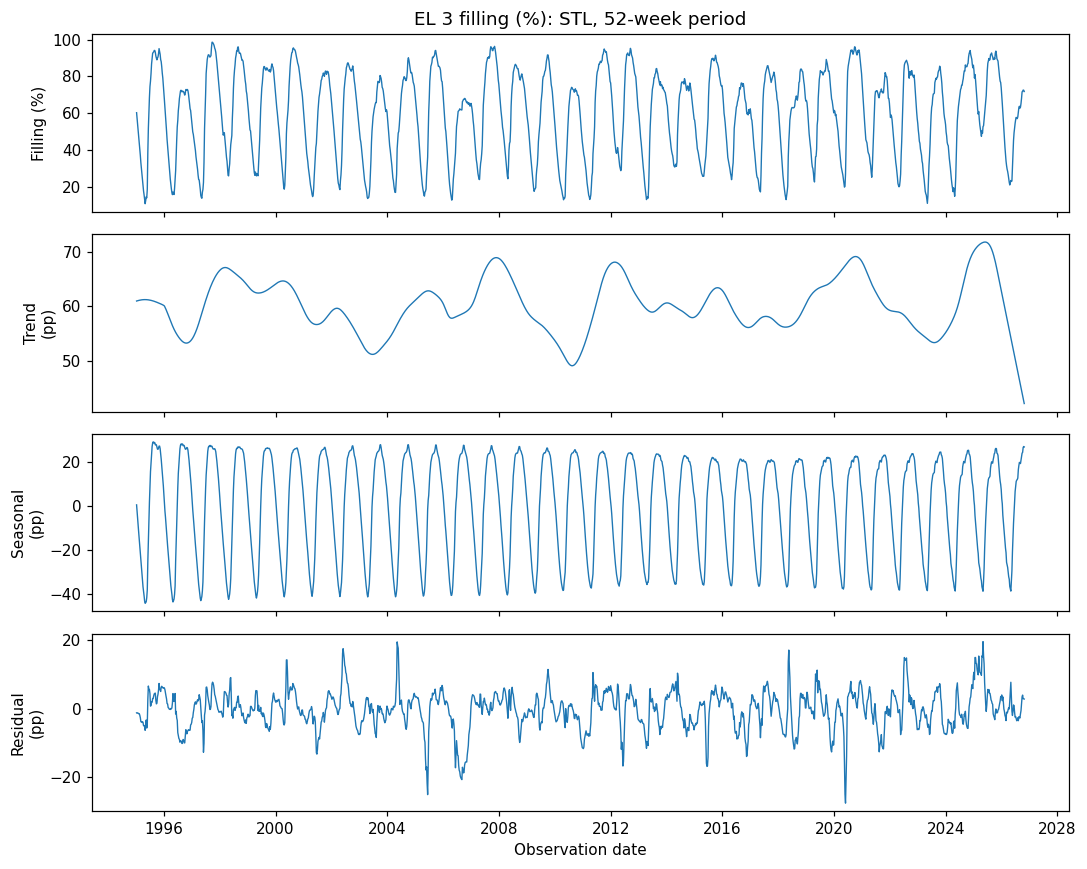

In [14]:
# Decompose all available weeks; this is not restricted to the weather year 2024.
components, stl_summary, fig = stl_analysis(weekly)
print(stl_summary)
plt.show()

In [15]:
# Reconstruction is an essential check for an additive decomposition.
assert components.index.equals(weekly.index)
assert np.allclose(components.trend + components.seasonal + components.residual, weekly)
changed_components, _, check_fig = stl_analysis(weekly, seasonal=21, trend=157, robust=False)
assert not np.allclose(changed_components.trend, components.trend)
assert not np.allclose(changed_components.seasonal, components.seasonal)
plt.close(check_fig)
print("PASS: additive reconstruction and response to STL smoothing/robust controls.")

PASS: additive reconstruction and response to STL smoothing/robust controls.


## Spectrogram: changing cycles over time

The spectrogram divides the same weekly history into overlapping Hann windows
and estimates the power spectral density (PSD) in each window. The default window
is **104 weeks**, with **52 weeks of overlap**. Each window is detrended by
subtracting its mean. Longer windows improve frequency resolution but blur when
changes happen. More overlap gives closer window centers; it does not increase
the underlying frequency resolution.

Sampling frequency is **one observation per week**. Frequencies are in
**cycles/week**, so an annual cycle is approximately **1/52 cycles/week** and the
Nyquist frequency is **0.5 cycles/week**. Time is plotted at the window-center
date. Density is in **pp²/(cycles/week)** and displayed in decibels relative to
one unit of that density. A stronger color indicates stronger variation at that
frequency, not a higher filling level. The 104-week default resolves frequencies
in steps of 1/104 cycles/week, placing an annual cycle at the second nonzero bin.

{'weeks': 1660, 'windows': 30, 'frequency_step': 0.009615384615384616, 'peak_period_weeks': 52.0}


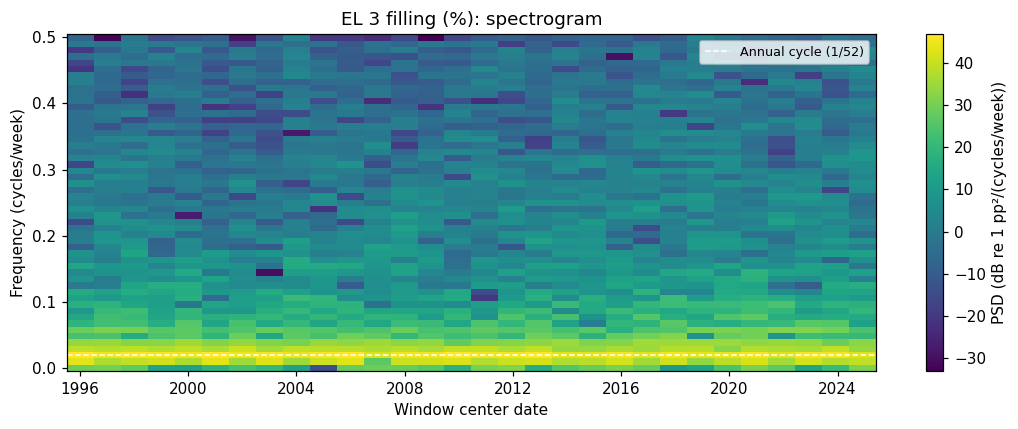

In [16]:
# Shared spectrum data has frequency rows and dated window-center columns.
spectrum, spectrum_summary, fig = filling_spectrogram(weekly)
print(spectrum_summary)
plt.show()

In [17]:
# Validate dimensions/units and recover a known annual signal in a controlled example.
assert np.isfinite(spectrum.to_numpy()).all() and (spectrum.to_numpy() >= 0).all()
assert spectrum.shape[0] == 104 // 2 + 1
assert np.isclose(spectrum.index.max(), 0.5)
assert np.isclose(np.diff(spectrum.index).mean(), 1 / 104)
assert (spectrum.columns.to_series().diff().dropna() == pd.Timedelta(weeks=52)).all()
changed_spectrum, _, check_fig = filling_spectrogram(weekly, window=156, overlap=104)
assert changed_spectrum.shape[0] != spectrum.shape[0]
plt.close(check_fig)
annual = pd.Series(
    50 + 10 * np.sin(2 * np.pi * np.arange(520) / 52),
    index=pd.date_range("2000-01-02", periods=520, freq="7D"), name="Known annual signal"
)
_, known_summary, check_fig = filling_spectrogram(annual)
assert np.isclose(known_summary["peak_period_weeks"], 52)
plt.close(check_fig)
print("PASS: nonnegative spectrum, time/frequency units, window controls, and known annual cycle.")

PASS: nonnegative spectrum, time/frequency units, window controls, and known annual cycle.


## Visible input checks

Invalid parameters must produce readable errors rather than misleading plots.
These small checks stay in the notebook as required; no separate test framework
is added. The analyses are exploratory, and their defaults are not tuned on an
independent evaluation set.

In [18]:
# Check the public parameter boundaries and reject an incomplete weather day.
checks = [
    (lambda: precipitation_analysis(daily.precipitation, cutoff=len(daily)), "DCT cutoff"),
    (lambda: precipitation_analysis(daily.precipitation, multiplier=0), "SPC multiplier"),
    (lambda: temperature_analysis(daily.temperature_2m, contamination=0), "LOF contamination"),
    (lambda: stl_analysis(weekly, seasonal=12), "Even seasonal smoother"),
    (lambda: stl_analysis(weekly, trend=51), "Short trend smoother"),
    (lambda: filling_spectrogram(weekly, window=104, overlap=104), "Spectrogram overlap"),
    (lambda: daily_weather(hourly.iloc[1:]), "Incomplete UTC day"),
    (lambda: fetch_weather("unknown", "2024-01-01", "2024-12-31"), "Unknown area"),
]
for operation, label in checks:
    try:
        operation()
    except ValueError:
        print("PASS:", label)
    else:
        raise AssertionError(f"Expected a ValueError: {label}")
print("All visible Part 3 function checks passed.")

PASS: DCT cutoff
PASS: SPC multiplier
PASS: LOF contamination
PASS: Even seasonal smoother
PASS: Short trend smoother
PASS: Spectrogram overlap
PASS: Incomplete UTC day
PASS: Unknown area
All visible Part 3 function checks passed.


## Streamlit counterpart and delivery status

The **Reservoir analysis** page has its own area selector and STL/Spectrogram
tabs. It uses full history, reports interpolated weeks, and exposes the same
parameters used here. The **Weather quality** page has its own eight-area
selector and a complete-calendar-year selector initially set to 2024. Its
Precipitation/Temperature tabs call the same analysis functions. A one-day
Streamlit cache is keyed by area and year; changing only a plot parameter reuses
the hourly download. These pages read no local database credentials.

The public project links are the [GitHub repository](https://github.com/dared22/ind320)
and [Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/).
Part 3 stays on the temporary branch `part3-data-quality` for peer review.
The public app may continue to serve the earlier branch until the new branch is
deployed. Peer review, public deployment verification, screencast recording, and
Canvas submission remain student delivery steps. The plan records a deadline of
November 10, 2026, at 23:59; verify the deadline in Canvas before submitting.

For a PDF after **Run All**, install Tectonic and run
`uv run python scripts/export_part3_pdf.py`. The notebook dependency group includes
Pandoc and nbconvert; the exporter wraps long code and output lines for printing.
The committed PDF records the executed outputs; rerun and re-export after changes.

## AI-tool use

AI assistance was used to implement the shared Python functions, build the two
Streamlit pages, draft this notebook, and run checks and PDF export. The agent
also consulted the course and library documentation. AI-generated explanations
and anomaly flags require review: the student remains responsible for
understanding the code, interpreting the results, checking course requirements,
and reporting AI use honestly. This statement describes the assistance used; it
does not claim the student has independently verified every result.

## Compulsory-work log

For Part 3, the project extends the Norwegian reservoir dashboard with weather
and data-quality analysis. The main task was to keep the work reproducible in a
Jupyter Notebook while making the same calculations available in Streamlit.
Reusable functions handle the weather download, the two anomaly methods, and the
reservoir analyses. The notebook explains those functions and shows their outputs
alongside visible checks.

Area preparation uses the supplied electricity-area and NVE-region shapefiles.
The electricity polygons provide NO1 to NO5. The NVE polygons are combined into
East, West, and North as an approximation for precipitation areas. They are not
presented as exact catchments. A fixed random seed produces 1,000 candidate
points per area and one chosen point from each group. Saving the eight chosen
coordinates to CSV lets the app use the same locations without installing GIS
libraries on Streamlit Cloud.

The weather example downloads hourly ERA5 precipitation and temperature for NO3
throughout 2024. Using UTC makes the leap-year timeline straightforward to check.
The daily precipitation plot averages hourly amounts rather than calculating a
rainfall total, so its label needs to make that distinction clear. The notebook
also records the difference between the sampled coordinate and the ERA5 grid
cell returned by the service.

Precipitation is explored with a DCT high-pass filter and robust SPC limits.
Temperature uses Local Outlier Factor. Both plots keep the original observations
visible and mark unusual dates without deleting them. Changing the parameters
shows that a flagged day depends on the method and threshold. These flags are
starting points for inspection, not automatic evidence of incorrect measurements.
For reservoir filling, STL and the spectrogram use the full weekly history,
independently of the weather year. Reconstruction and a known annual signal help
check that the decomposition and frequency units behave as intended.

In Streamlit, each new page has its own area selector. Tabs group related plots,
and the weather cache separates downloads from plot controls. Notebook checks
cover sampling, weather coverage, daily averages, analysis parameters, and invalid
inputs. The [public repository](https://github.com/dared22/ind320) and
[Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/) link the development
and online parts of the work. Part 3 remains on a temporary branch for peer
review. Public deployment verification, the screencast, and submission still need
to be completed before the final delivery.